# Week (1) Module A: Data Inspection & Variable Types
**Course:** Statistics and Machine Learning

---

### Module Contributor(s)
| Full Name | Role |
|---|---|
| `_______________` | `_______________` |
| `_______________` | `_______________` |

---

### About this Module
This module covers **Tasks 1, 2, and 3** of the Week (1) practical.
Your outputs will be merged with **Modules B, C, and D into the group's final notebook**.

**Dataset:** Pima Indians Diabetes -> DOI: https://www.openml.org/d/37

| Feature | Description |
|---|---|
| `Pregnancies` | Number of pregnancies |
| `Glucose` | Plasma glucose concentration |
| `BloodPressure` | Diastolic blood pressure (mm Hg) |
| `SkinThickness` | Triceps skin fold thickness (mm) |
| `Insulin` | 2-hour serum insulin (mu U/ml) |
| `BMI` | Body mass index |
| `DiabetesPedigreeFunction` | Genetic risk score |
| `Age` | Age in years |
| `Outcome` | 0 = Non-diabetic, 1 = Diabetic |


---

**Background: Day 1 lecture recap:**

Statistics is the science of collecting, analysing, interpreting, and organising data. Before any analysis or modelling can begin, you must understand what you are working with. 

>The key steps are:
- **Data inspection:** understand the shape, column types, and range of values in the dataset.
- **Variable types:** every column is either *categorical* (labels, no arithmetic meaning), *discrete* (countable whole numbers), or *continuous* (measurable, any real value in a range). The type determines which statistics and visualisations are valid.
- **Data quality:** real-world data is rarely clean. Missing values are often disguised as impossible zeros (e.g. Glucose = 0 is clinically impossible). Identifying and handling these before computing any statistics is a prerequisite — not an afterthought.
- **Descriptive statistics** (covered further in Module B) summarise data through *central tendency* (mean, median, mode) and *dispersion* (variance, standard deviation, range).
---
> Cells marked `# TODO` require code. Cells marked `✍️` require a written response.

---
# Task 1: Inspect & Summarise the Dataset
Before any analysis, always explore the structure and basic properties of the data.
> **Goal:** Understand the shape, types, and quality of the data before any analysis.

In [1]:
# ── Task 1 Setup (do not modify) ──────────────────────────────────────────────

# pandas: tabular data manipulation (DataFrames, reading CSV, groupby, etc.)
import pandas as pd

# numpy: numerical operations on arrays (mean, random, etc.)
import numpy as np

# Load the Pima Indians Diabetes dataset directly from a public GitHub URL.
# This avoids any local file dependency — the dataset is always fresh.
URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
df = pd.read_csv(URL)

# The 'Outcome' column stores 0 (Non-Diabetic) and 1 (Diabetic) as integers.
# We add a human-readable string column 'DiabetesStatus' for use in plot labels
# and groupby operations, while keeping 'Outcome' for arithmetic (e.g. .mean()).
df['DiabetesStatus'] = df['Outcome'].map({0: 'Non-Diabetic', 1: 'Diabetic'})

print(f'Dataset loaded: {df.shape[0]} rows x {df.shape[1]} columns')


Dataset loaded: 768 rows x 10 columns


In [2]:
# Provided: inspect the dataset shape and data types

# df.shape returns a tuple (n_rows, n_columns) — always the first sanity check.
print('Shape:', df.shape)

# df.dtypes shows the pandas dtype inferred for each column:
#   int64   -> whole numbers (could be discrete or categorical stored as int)
#   float64 -> decimal numbers (continuous measurements)
#   object  -> strings / mixed types
# Knowing the dtype is the first step in deciding which statistics are valid.
print('\nData types:')
print(df.dtypes)


Shape: (768, 10)

Data types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
DiabetesStatus               object
dtype: object


In [3]:
# Provided: detect both explicit and implicit missing values

# --- Explicit missing values ---
# df.isnull() returns a boolean DataFrame (True where NaN).
# .sum() counts Trues column-by-column.
# Result: 0 for every column means there are NO explicit NaNs in this dataset.
print('Explicit missing values (NaN):')
print(df.isnull().sum())

# --- Implicit missing values ---
# In medical datasets, zeros are often used as placeholders for unmeasured values.
# A Glucose of 0, a BMI of 0, or Blood Pressure of 0 are clinically impossible
# they indicate a missing measurement, not an actual reading of zero.
# We only flag these columns; 'Pregnancies' and 'Age' can legitimately be 0.
suspect_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
print('\nZero counts in clinically implausible columns:')
# (df[suspect_cols] == 0) produces a boolean DataFrame; .sum() counts zeros per column.
print((df[suspect_cols] == 0).sum())


Explicit missing values (NaN):
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
DiabetesStatus              0
dtype: int64

Zero counts in clinically implausible columns:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [4]:
# TODO: Generate a full summary statistics table for the dataset.
# Use .describe() rounded to 2 decimal places.

# YOUR CODE HERE


In [5]:
# TODO: Print the count of Diabetic vs Non-Diabetic patients.
# Also compute and print the percentage split.
# Hint: use value_counts() with normalize=True for percentages.

# YOUR CODE HERE


### ✍️ Interpretation: Task 1

1. How many patients are Diabetic vs Non-Diabetic? Is the dataset balanced? Why does class balance matter?
2. Which feature has the highest mean value? What might this mean clinically?
3. What data quality concerns did you notice from the zero counts? How might you handle them in a real project?

> *Your answer here:*

---
# Task 2: Identify Variable Types
Knowing whether a variable is categorical, discrete, or continuous determines which statistics and tests are appropriate.

> **Goal:** Classify each column and explain why variable type determines which statistics and tests are valid.

In [6]:
# ── Task 2 Setup (do not modify) ──────────────────────────────────────────────

# Each task reloads the dataset independently so modules can run in any order.
import pandas as pd

URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
df = pd.read_csv(URL)
df['DiabetesStatus'] = df['Outcome'].map({0: 'Non-Diabetic', 1: 'Diabetic'})
print('Ready')


Ready


In [7]:
# Provided: count unique values per column — a key clue for variable type classification

# df.nunique() returns the number of distinct values in each column.
# Rules of thumb:
#   2 unique values           -> binary categorical (e.g. Outcome: 0/1)
#   small count of integers   -> likely discrete (e.g. Pregnancies: 0-17)
#   large count, decimals     -> likely continuous (e.g. BMI, DiabetesPedigreeFunction)
# This is a heuristic — context always overrides the count.
print('Number of unique values per column:')
print(df.nunique())


Number of unique values per column:
Pregnancies                  17
Glucose                     136
BloodPressure                47
SkinThickness                51
Insulin                     186
BMI                         248
DiabetesPedigreeFunction    517
Age                          52
Outcome                       2
DiabetesStatus                2
dtype: int64


In [15]:
# TODO: Complete the variable type classification.
# Replace each '???' with: 'Continuous', 'Discrete', or 'Categorical'
# Add a brief justification in the 'Reason' column.

variable_types = {
    'Pregnancies':               {'Type': 'Discrete', 'Reason': 'A pregnancy can only be a whole number'},
    'Glucose':                   {'Type': 'Continuous', 'Reason': 'Glucose is a concentration value that can occur in a given range'},
    'BloodPressure':             {'Type': 'Continuous', 'Reason': 'This is measured in mm Hg (millimeter column of mercury), which is a physical measurement, and not a count'},
    'SkinThickness':             {'Type': 'Continuous', 'Reason': 'Measured in mm, a measurement'},
    'Insulin':                   {'Type': 'Continuous', 'Reason': 'A measurement, can be any positive real value'},
    'BMI':                       {'Type': 'Continuous', 'Reason': 'Body mass index (weight/height) - a ratio, subsequently a fraction / decimal'},
    'DiabetesPedigreeFunction':  {'Type': 'Continuous', 'Reason': 'A computed decimal value for genetic risk scoring'},
    'Age':                       {'Type': 'Discrete', 'Reason': 'Age is recorded in whole'},
    'Outcome':                   {'Type': 'Categorical', 'Reason': 'Either diabetic/non-diabetic. Can be one possible outcome'},
}

type_df = pd.DataFrame(variable_types).T
print(type_df)

                                 Type  \
Pregnancies                  Discrete   
Glucose                    Continuous   
BloodPressure              Continuous   
SkinThickness              Continuous   
Insulin                    Continuous   
BMI                        Continuous   
DiabetesPedigreeFunction   Continuous   
Age                          Discrete   
Outcome                   Categorical   

                                                                     Reason  
Pregnancies                          A pregnancy can only be a whole number  
Glucose                   Glucose is a concentration value that can occu...  
BloodPressure             This is measured in mm Hg (millimeter column o...  
SkinThickness                                 Measured in mm, a measurement  
Insulin                       A measurement, can be any positive real value  
BMI                       Body mass index (weight/height) - a ratio, sub...  
DiabetesPedigreeFunction  A computed decima

### ✍️ Interpretation: Task 2

1. Why does variable type matter when choosing a statistical test or visualisation?
2. `Outcome` is stored as an integer (0/1) but is treated as categorical. Why is this distinction important?
3. `Pregnancies` has only 17 unique values — does that make it discrete or continuous? Explain your reasoning.

> *Your answer here:*
1. Data can either be categorical or numerical. Thee type of test or chart to be used on the data depends critically on the variable types. For example, calculating the mean on the outcome, which is a categorical variable, may not be meaningful. Meanwhile, on a continuous variable like glucose, we can further derive the mean and standard deviation.
2. The possible values for outcomes are either 0 or 1. This is convenient for readability and consistency in code, avoiding errors. The values are practically mapped to their categories: Diabetic/Non-Diabetic
3. The pregnancy count for a particular record, is the event of pregnancies for that record. So a person, could either have 2 or 3 pregnancies, or 0. The number of pregnancies for one person, may be different for another. These events are unique per person. The events are recorded in whole. 

---
# Task 3: Data Quality: Zeros as Hidden Missing Values

In this dataset, several columns use 0 as a placeholder for missing measurements (a common problem in real-world medical data). Before computing any statistics, we must handle these values deliberately.

> **Goal:** Detect implausible zeros, replace them with NaN, and compare how summary statistics change before and after.

In [9]:
# ── Task 3 Setup (do not modify) ──────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent visual theme for all plots in this task.
# 'whitegrid' adds horizontal grid lines; 'muted' uses softer colours.
sns.set_theme(style='whitegrid', palette='muted')

# Default figure size for all matplotlib plots in this task (width x height in inches).
plt.rcParams['figure.figsize'] = (10, 4)

URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'

# We name this df_raw to make it explicit that this is the unmodified original.
# The student will create df_clean as a separate copy — never overwriting this one.
df_raw = pd.read_csv(URL)
df_raw['DiabetesStatus'] = df_raw['Outcome'].map({0: 'Non-Diabetic', 1: 'Diabetic'})

# These five columns can contain zeros that are clinically impossible.
# Defined here so they are reused consistently across all cells in Task 3.
SUSPECT_COLS = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
print('Ready')


Ready


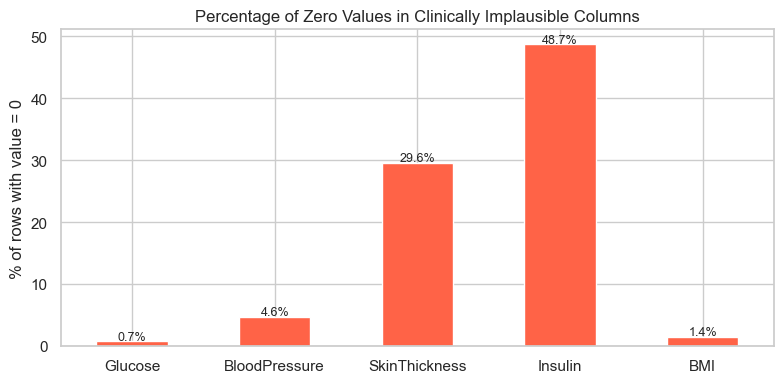

In [10]:
# Provided: visualise the percentage of zero values in each suspect column

# Step 1: (df_raw[SUSPECT_COLS] == 0) produces a boolean DataFrame.
#         .sum() counts the True values (i.e. zeros) per column.
zero_counts = (df_raw[SUSPECT_COLS] == 0).sum()

# Step 2: Convert to a percentage of total rows for easier interpretation.
#         e.g. Insulin has ~49% zeros — nearly half the column is missing!
zero_pct = (zero_counts / len(df_raw) * 100).round(1)

# Step 3: Plot as a bar chart so the severity is immediately visible.
fig, ax = plt.subplots(figsize=(8, 4))
zero_pct.plot(kind='bar', ax=ax, color='tomato', edgecolor='white')
ax.set_title('Percentage of Zero Values in Clinically Implausible Columns')
ax.set_ylabel('% of rows with value = 0')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=0)

# Step 4: Annotate each bar with its exact percentage value.
for i, v in enumerate(zero_pct):
    ax.text(i, v + 0.3, f'{v}%', ha='center', fontsize=9)

plt.tight_layout()
plt.show()


In [11]:
# TODO: Create a cleaned copy of the dataset called df_clean.
# Replace zeros in SUSPECT_COLS with NaN using .replace(0, np.nan).
# Then print the new NaN count per column to confirm.

# YOUR CODE HERE
# df_clean = df_raw.copy()
# df_clean[SUSPECT_COLS] = ...


In [12]:
# TODO: Build a comparison table showing the mean and median of each SUSPECT_COL
# before (df_raw) and after (df_clean) replacing zeros.
# Present as a DataFrame with columns: Feature | Raw Mean | Clean Mean | Raw Median | Clean Median
# Round all values to 2 decimal places.

# YOUR CODE HERE


In [13]:
# TODO: Plot side-by-side histograms for 'Insulin':
# Left panel = raw (including zeros), Right panel = cleaned (zeros removed).
# Add a vertical line for the mean on each panel.
# Use plt.subplots(1, 2, figsize=(12, 4)).

# YOUR CODE HERE


### ✍️ Interpretation: Task 3

1. Which feature was most affected (largest mean shift) by removing zeros? Why does removing zeros increase the mean?
2. Did the median shift by more or less than the mean? Relate this to what you know about median robustness.
3. If you were building a predictive model, would you drop rows with NaN or impute them? What are the trade-offs?

> *Your answer here:*

---
## 📋 Module A: Handoff Summary

Complete this before merging with your group. It helps teammates understand your findings quickly.

| Item | Your finding |
|---|---|
| Dataset size | ??? rows × ??? columns |
| Class balance | ???% Diabetic / ???% Non-Diabetic |
| Main data quality issue | ??? |
| Feature with highest mean (raw) | ??? |
| Feature most affected by zero-removal | ??? (mean shifted by ???) |
| Any columns that are categorical despite being stored as int | ??? |

> Fill in the table above before handing off to the group.